# SensorTSLM — Project And Evaluation Status Notebook

This notebook is the current project-facing status view for the repository.
It is meant to answer three questions concretely:

1. What is already implemented in the repo?
2. What is implemented specifically for the paper evaluation benchmark?
3. What is still missing for each LaTeX table / figure?

## LaTeX Mapping

- **Table 1**: model/training overview. This notebook documents which rows are currently runnable vs. still blocked by training.
- **Table 2**: binary activity detection. See Section 3.
- **Table 3**: metabolic prediction. See Section 4.
- **Table 4**: sleep 2-class and 8-class activity classification. Status only; not implemented yet.
- **Table 5**: sensor-text retrieval. Status only; not implemented yet.
- **Table 6**: difficulty ladder / overview. Status summary is in Section 1.
- **Candidate qualitative figures**:
  - daily captioning example from the caption pipeline
  - activity-window input example
  - weekly metabolic input example

## Important Scope Distinction

This notebook separates:

- **Project-wide pipeline**: transform sensor data, generate captions/annotations, visualize signals, export caption data.
- **Evaluation benchmark pipeline**: `evaluation/run_eval.py` + task/dataset classes for Table 2 / Table 3 style benchmark runs.
- **Training pipeline**: Stage 1 caption training and Stage 2 task fine-tuning for OpenTSLM or fine-tuned VLMs.

The training pipeline is only partially represented in this repo today. That is why some paper rows are conceptually defined but not yet runnable.

In [1]:
import sys
from pathlib import Path
from collections import Counter

repo_root = Path.cwd().resolve()
if not (repo_root / 'README.md').exists():
    repo_root = repo_root.parent.resolve()
sys.path.insert(0, str(repo_root))

import datasets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

DAILY_DIR = repo_root / 'data' / 'mhc_dev_subset_hf'
WEEKLY_DIR = repo_root / 'data' / 'mhc_dev_subset_weekly_hf'
LABELS_PATH = repo_root / 'data' / 'labels_dev_subset.parquet'
FIG_DIR = repo_root / 'notebooks' / 'figures'

print(f'repo_root   : {repo_root}')
print(f'daily dir   : {DAILY_DIR}')
print(f'weekly dir  : {WEEKLY_DIR}')
print(f'labels path : {LABELS_PATH}')

labels_df = pd.read_parquet(LABELS_PATH)
daily_ds = datasets.load_from_disk(str(DAILY_DIR))
weekly_ds = datasets.load_from_disk(str(WEEKLY_DIR))

print(f'Daily rows  : {len(daily_ds):,}')
print(f'Weekly rows : {len(weekly_ds):,}')
print(f'Label users : {len(labels_df):,}')
print(f'Label cols  : {len(labels_df.columns):,}')

/Users/milanagurbanova/Coding_Projects/Stanford/SensorLM/sensorlm-env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


repo_root   : /Users/milanagurbanova/Coding_Projects/Stanford/SensorLM
daily dir   : /Users/milanagurbanova/Coding_Projects/Stanford/SensorLM/data/mhc_dev_subset_hf
weekly dir  : /Users/milanagurbanova/Coding_Projects/Stanford/SensorLM/data/mhc_dev_subset_weekly_hf
labels path : /Users/milanagurbanova/Coding_Projects/Stanford/SensorLM/data/labels_dev_subset.parquet
Daily rows  : 130,102
Weekly rows : 29,009
Label users : 352
Label cols  : 174


---
## Section 1 — Repo Status Map

**LaTeX references:** Table 1, Table 6.

This section is the most important status snapshot. It distinguishes what exists in the repository at all from what is already wired into the benchmark runner.

In [2]:
from evaluation.run_eval import DATASET_REGISTRY, TASK_REGISTRY

project_status = pd.DataFrame([
    {
        'Area': 'Daily sensor transform',
        'Status': 'implemented',
        'Files': 'mhc/dataset.py, mhc/transformer.py',
        'Needed for': 'captioning + daily eval',
        'Notes': 'Loads 19-channel per-day MHC recordings and converts heart rate to BPM.',
    },
    {
        'Area': 'Caption extractors',
        'Status': 'implemented',
        'Files': 'extractors/*.py, detectors/*.py',
        'Needed for': 'caption generation',
        'Notes': 'Statistical, structural, and semantic caption generation are present.',
    },
    {
        'Area': 'Caption pipeline orchestration',
        'Status': 'implemented',
        'Files': 'annotator.py, captionizer.py, visualizer.py',
        'Needed for': 'Stage 1 data creation',
        'Notes': 'Can annotate recordings and visualize them; no full training script here.',
    },
    {
        'Area': 'Caption export for OpenTSLM dataset',
        'Status': 'implemented but not materialized in repo',
        'Files': 'exporters/lean.py, time_series_datasets/mhc_caption_qa_dataset.py',
        'Needed for': 'OpenTSLM Stage 1',
        'Notes': 'Code exists, but there is currently no exported `exports/recordings_*.arrow` directory in the repo.',
    },
    {
        'Area': 'OpenTSLM training / fine-tuning',
        'Status': 'not implemented in this repo',
        'Files': 'external / missing',
        'Needed for': 'official Table 1 zero-shot + fine-tuned rows',
        'Notes': 'This is the missing training arm: Stage 1 caption training and Stage 2 task tuning.',
    },
    {
        'Area': 'VLM benchmark runner',
        'Status': 'implemented',
        'Files': 'evaluation/*, models/*',
        'Needed for': 'Table 2 / Table 3 prompt-based evaluation',
        'Notes': 'Runs prompt-based classification from plotted sensor channels.',
    },
    {
        'Area': 'Retrieval / log-prob scoring backend',
        'Status': 'not implemented',
        'Files': 'missing',
        'Needed for': 'Table 5',
        'Notes': 'Current model interface exposes text generation, not caption scoring or token logprobs.',
    },
])

benchmark_status = pd.DataFrame([
    {
        'Paper item': 'Table 2 — activity yes/no',
        'Current status': 'partial',
        'Wired in run_eval?': 'yes',
        'Exact paper coverage today': 'binary yes/no over windows, but not per-activity reporting and not pairwise protocol',
        'Blocked by training?': 'only for official Stage 1/Stage 2 rows',
    },
    {
        'Paper item': 'Table 3 — metabolic binary subset',
        'Current status': 'partial-to-usable',
        'Wired in run_eval?': 'yes',
        'Exact paper coverage today': 'BiologicalSex, Diabetes, Hypertension, cardiovascular disease, BMI are wired; Happiness/BP/Sleep category variants still missing',
        'Blocked by training?': 'only for official Stage 1/Stage 2 rows',
    },
    {
        'Paper item': 'Table 4 — sleep 2-class',
        'Current status': 'missing',
        'Wired in run_eval?': 'no',
        'Exact paper coverage today': 'dataset + task missing',
        'Blocked by training?': 'no, first blocked by missing eval code',
    },
    {
        'Paper item': 'Table 4 — activity 8-class',
        'Current status': 'missing',
        'Wired in run_eval?': 'no',
        'Exact paper coverage today': 'dataset + task missing',
        'Blocked by training?': 'no, first blocked by missing eval code',
    },
    {
        'Paper item': 'Table 5 — retrieval',
        'Current status': 'missing',
        'Wired in run_eval?': 'no',
        'Exact paper coverage today': 'no scoring API, no retrieval task, no logprob/perplexity path',
        'Blocked by training?': 'partly, but first blocked by missing eval/code interface',
    },
    {
        'Paper item': 'Official zero-shot rows',
        'Current status': 'missing',
        'Wired in run_eval?': 'not by itself',
        'Exact paper coverage today': 'prompt-only VLM baseline is possible; caption-trained Stage 1 model is not',
        'Blocked by training?': 'yes',
    },
    {
        'Paper item': 'Official fine-tuned rows',
        'Current status': 'missing',
        'Wired in run_eval?': 'not by itself',
        'Exact paper coverage today': 'task runner exists, but the training outputs do not',
        'Blocked by training?': 'yes',
    },
])

print('Datasets registered in run_eval.py:')
print(sorted(DATASET_REGISTRY))
print()
print('Tasks registered in run_eval.py:')
print(sorted(TASK_REGISTRY))
print()
print('Project-wide status:')
display(project_status)
print('Benchmark / paper-table status:')
display(benchmark_status)


Datasets registered in run_eval.py:
['mhc_activity', 'mhc_metabolic_biological_sex', 'mhc_metabolic_bmi', 'mhc_metabolic_cardiovascular', 'mhc_metabolic_diabetes', 'mhc_metabolic_hypertension']

Tasks registered in run_eval.py:
['activity', 'metabolic_biological_sex', 'metabolic_bmi', 'metabolic_cardiovascular', 'metabolic_diabetes', 'metabolic_hypertension']

Project-wide status:


,Area,Status,Files,Needed for,Notes
0,Daily sensor transform,implemented,"mhc/dataset.py, mhc/transformer.py",captioning + daily eval,Loads 19-channel per-day MHC recordings and co...
1,Caption extractors,implemented,"extractors/*.py, detectors/*.py",caption generation,"Statistical, structural, and semantic caption ..."
2,Caption pipeline orchestration,implemented,"annotator.py, captionizer.py, visualizer.py",Stage 1 data creation,Can annotate recordings and visualize them; no...
3,Caption export for OpenTSLM dataset,implemented but not materialized in repo,"exporters/lean.py, time_series_datasets/mhc_ca...",OpenTSLM Stage 1,"Code exists, but there is currently no exporte..."
4,OpenTSLM training / fine-tuning,not implemented in this repo,external / missing,official Table 1 zero-shot + fine-tuned rows,This is the missing training arm: Stage 1 capt...
5,VLM benchmark runner,implemented,"evaluation/*, models/*",Table 2 / Table 3 prompt-based evaluation,Runs prompt-based classification from plotted ...
6,Retrieval / log-prob scoring backend,not implemented,missing,Table 5,Current model interface exposes text generatio...


Benchmark / paper-table status:


,Paper item,Current status,Wired in run_eval?,Exact paper coverage today,Blocked by training?
0,Table 2 — activity yes/no,partial,yes,"binary yes/no over windows, but not per-activi...",only for official Stage 1/Stage 2 rows
1,Table 3 — metabolic binary subset,partial-to-usable,yes,"BiologicalSex, Diabetes, Hypertension, cardiov...",only for official Stage 1/Stage 2 rows
2,Table 4 — sleep 2-class,missing,no,dataset + task missing,"no, first blocked by missing eval code"
3,Table 4 — activity 8-class,missing,no,dataset + task missing,"no, first blocked by missing eval code"
4,Table 5 — retrieval,missing,no,"no scoring API, no retrieval task, no logprob/...","partly, but first blocked by missing eval/code..."
5,Official zero-shot rows,missing,not by itself,prompt-only VLM baseline is possible; caption-...,yes
6,Official fine-tuned rows,missing,not by itself,"task runner exists, but the training outputs d...",yes


---
## Section 2 — Captioning Pipeline (Daily Qualitative Example)

**LaTeX references:** candidate qualitative figure for the paper methods / data-generation section, plus Table 1 Stage 1 data generation.

This is **not** the downstream evaluation runner. This is the repo's captioning side:

- load a daily MHC recording
- transform it into a `Recording`
- generate algorithmic annotations with the extractors
- visualize the day with the generated captions

This part is important because it is the source of the caption data that would later feed OpenTSLM Stage 1 training.

row_id           : mhc:-aXTpFj1LqIXTSOsfsgkY9T1:2021-02-02
user/date        : -aXTpFj1LqIXTSOsfsgkY9T1 / 2021-02-02
active channels  : 6
annotation counts: {'statistical': 7, 'structural': 1}

First 10 annotations:
- [statistical] The iPhone step count data exhibits a mean of 0.3 steps/min, a standard deviation of 2.0, and its extreme values are 0.0 and 30.0.
- [statistical] iPhone distance average 0.188 m/min, reaching a maximum of 21.500 and a minimum of 0.000, with a standard deviation of 1.439.
- [statistical] flights climbed (iPhone) exhibits a mean of 0.0 count/min, with peak and minimal values reaching 0.0 and 0.0, and a standard deviation of 0.0.
- [statistical] For the Apple Watch step count measurements, the mean is 1.0 steps/min, the standard deviation is 4.2, and the data lies between 0.0 and 40.7.
- [statistical] The average Apple Watch distance value is 0.730 m/min, with extremes at 28.731 (max) and 0.000 (min), and a std of 3.020.
- [statistical] The heart rate data exhi

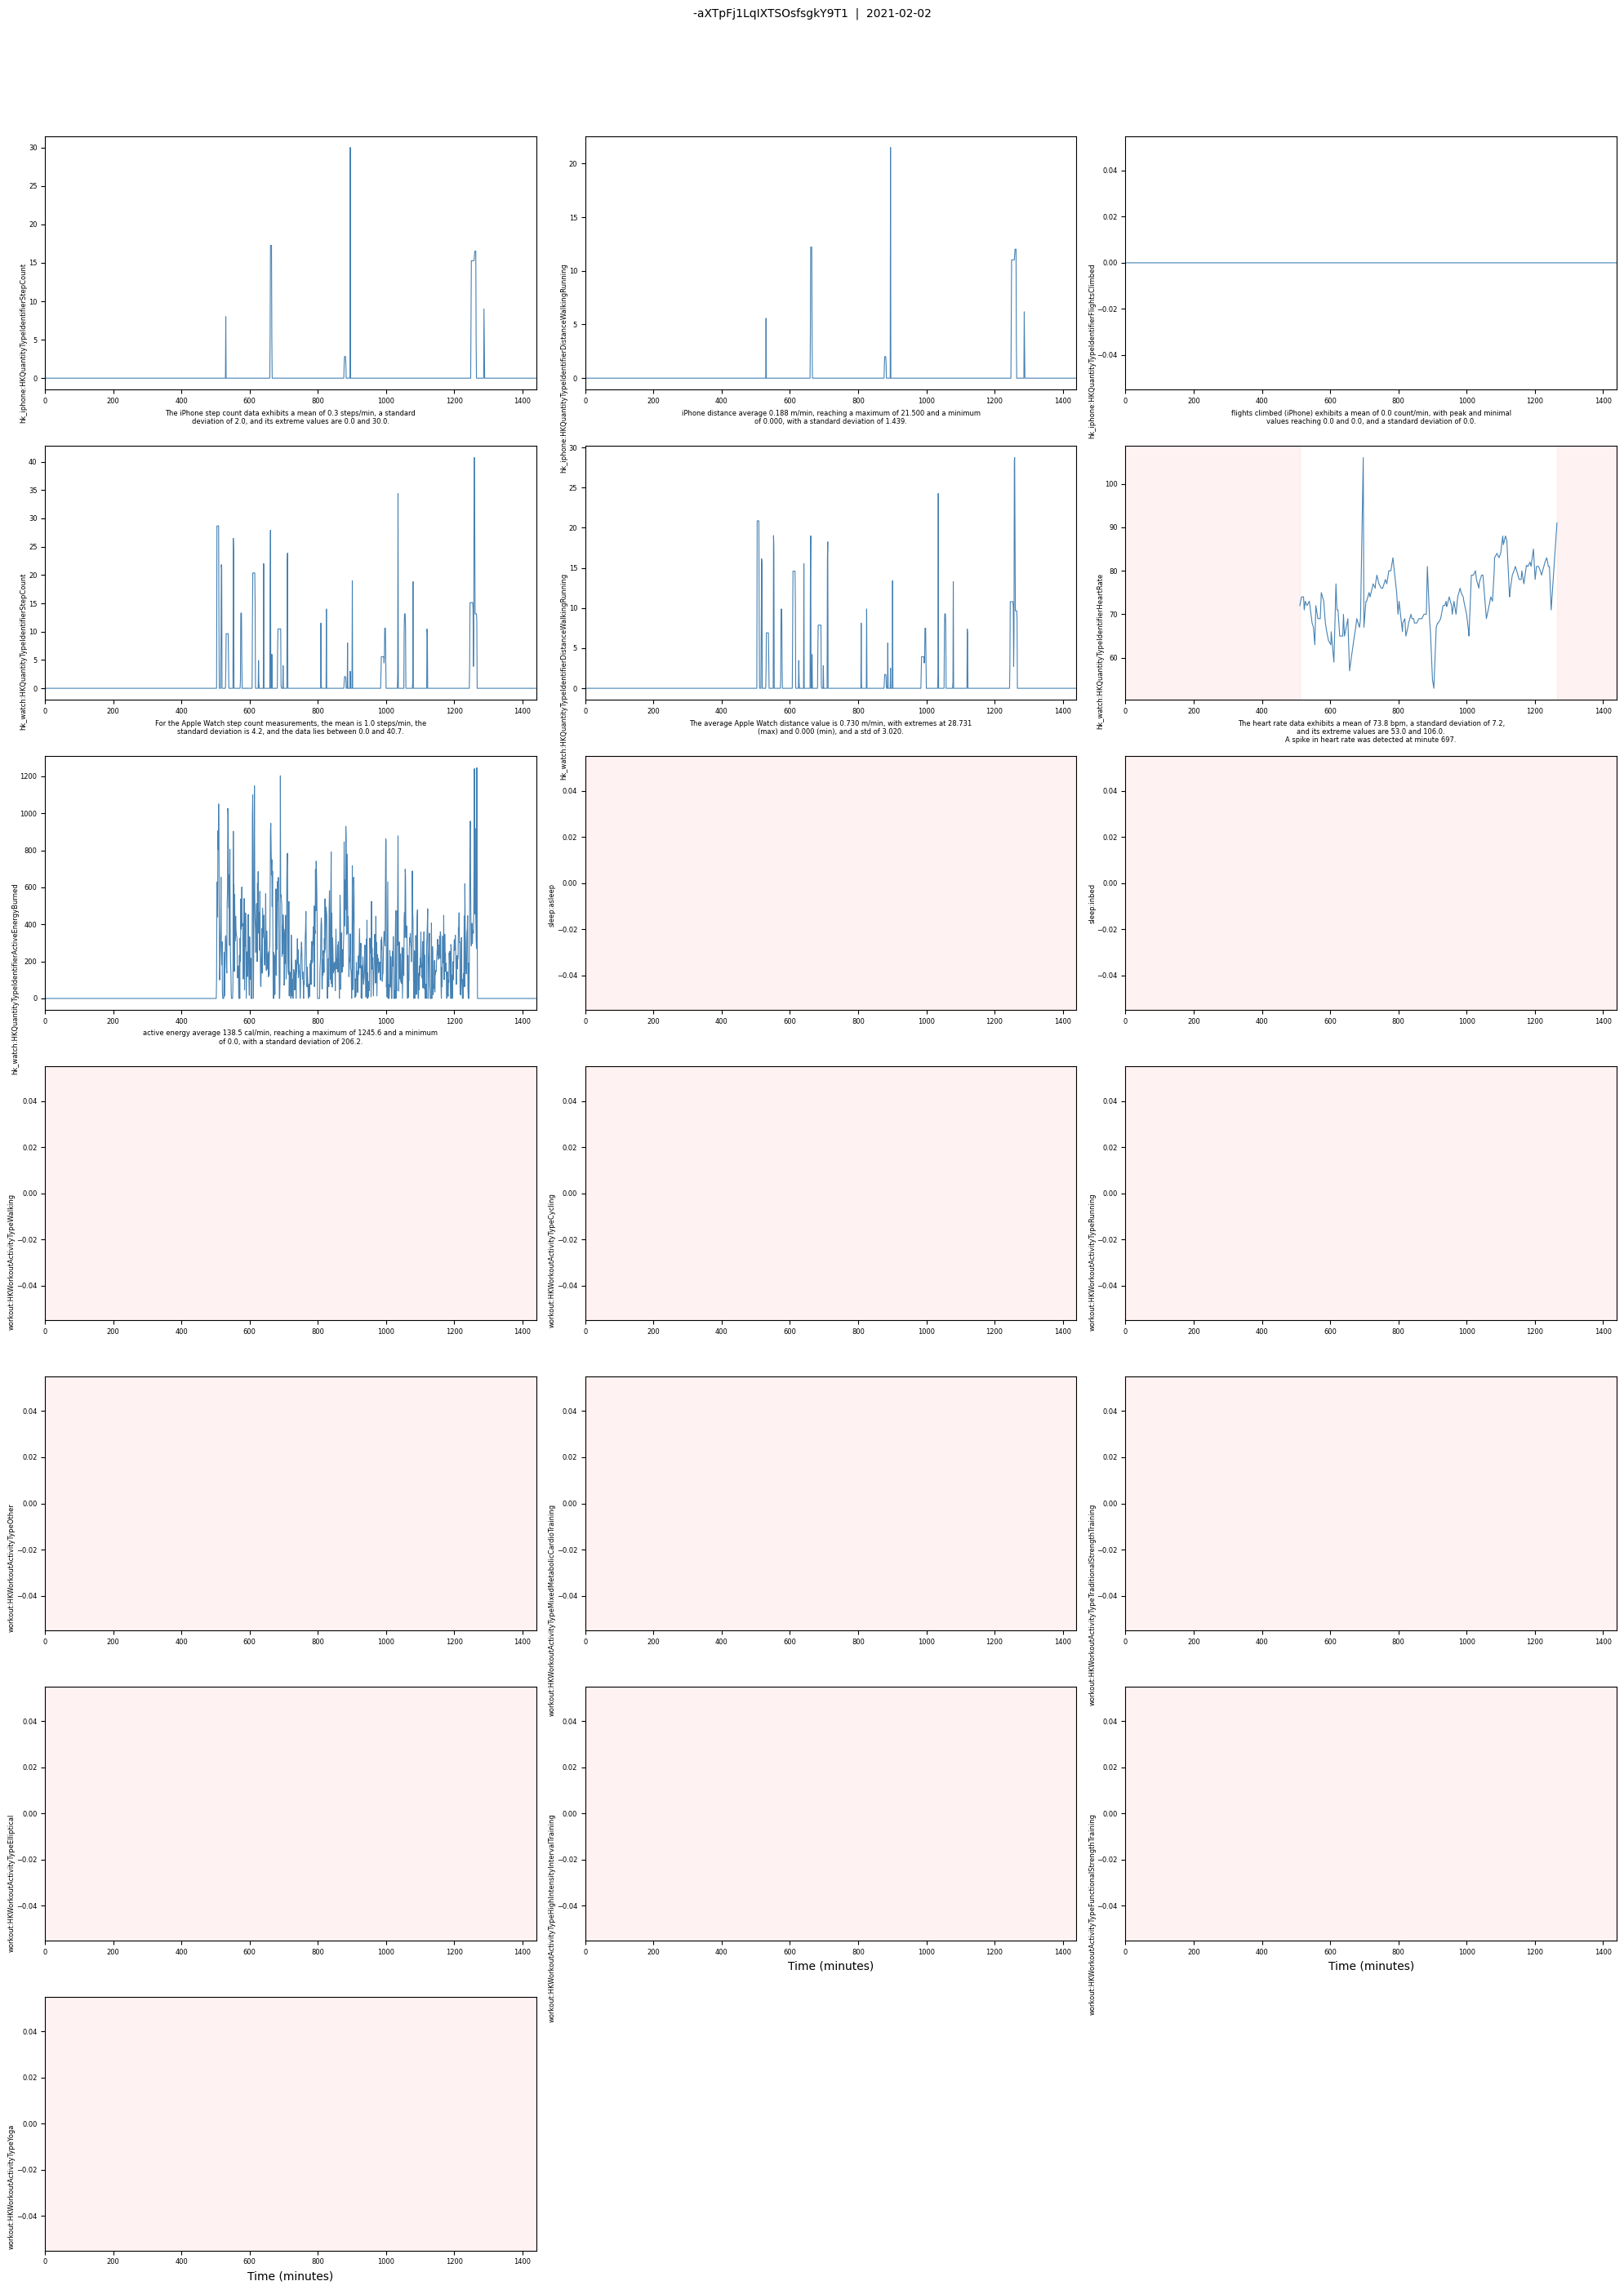


Saved: /Users/milanagurbanova/Coding_Projects/Stanford/SensorLM/notebooks/fig_caption_pipeline_daily_example.png


In [3]:
from annotator import Annotator
from extractors.semantic import SemanticExtractor
from extractors.statistical import StatisticalExtractor
from extractors.structural import StructuralExtractor
from mhc.constants import MHC_CHANNEL_CONFIG
from mhc.dataset import MHCDataset
from mhc.transformer import MHCTransformer
from visualizer import plot_row

caption_dataset = MHCDataset(min_wear_pct=50.0, dataset_dir=str(DAILY_DIR))
caption_row_raw = caption_dataset[0]
caption_recording = MHCTransformer().transform_row(caption_row_raw)
annotator = Annotator([
    StatisticalExtractor(MHC_CHANNEL_CONFIG),
    StructuralExtractor(MHC_CHANNEL_CONFIG),
    SemanticExtractor(MHC_CHANNEL_CONFIG),
])
caption_recording.annotations.extend(annotator.annotate(caption_recording))

annotation_counts = Counter(a.caption_type for a in caption_recording.annotations)
print(f'row_id           : {caption_recording.row_id}')
print(f'user/date        : {caption_recording.user_id} / {caption_recording.date}')
print(f'active channels  : {caption_recording.active_channel_count()}')
print(f'annotation counts: {dict(annotation_counts)}')
print()
print('First 10 annotations:')
for ann in caption_recording.annotations[:10]:
    print(f'- [{ann.caption_type}] {ann.text}')

fig = plot_row(caption_recording)
fig_path = FIG_DIR / 'fig_caption_pipeline_daily_example.png'
fig.savefig(fig_path, dpi=140, bbox_inches='tight')
print()
print(f'Saved: {fig_path}')


---
## Section 3 — Activity Evaluation Pipeline

**LaTeX references:** Table 2 and Table 6.

This section shows what the benchmark runner currently does for activity evaluation.

What is implemented today:

- `MHCActivityDataset`: 60-minute windows from daily MHC data
- labels from HealthKit workout channels
- `ActivityTask`: prompt asks a binary yes/no question
- `run_eval.py --dataset mhc_activity --task activity`

What is **not** implemented yet for exact Table 2 reproduction:

- per-activity metrics as separate columns in the final output table
- the alternative pairwise activity protocol mentioned in the paper text

Scanning MHC (test): 100%|██████████| 500/500 [00:01<00:00, 403.20it/s]

MHCActivityDataset (test): 15 samples (11 positive, 4 negative)


,activity,positive_windows,pct_of_positive_windows
0,walking,8,72.73
1,cycling,1,9.09
2,other workout,1,9.09
3,running,1,9.09


Total activity samples in dataset object : 15
Positive windows                         : 11
Negative windows                         : 4


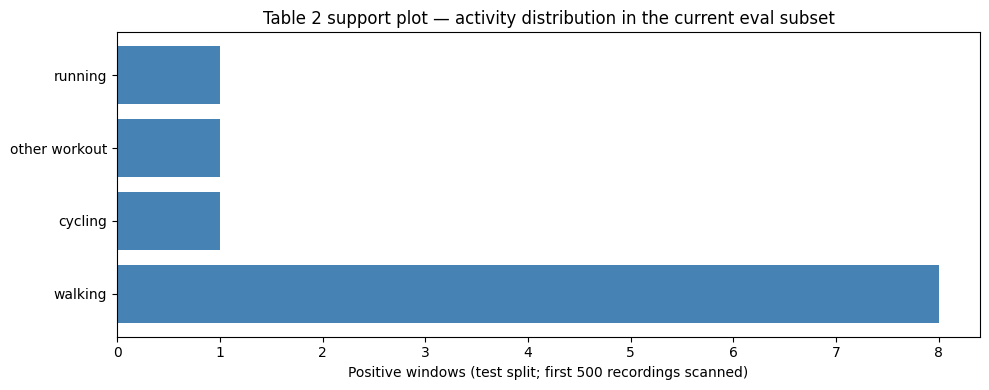

Saved: /Users/milanagurbanova/Coding_Projects/Stanford/SensorLM/notebooks/fig_activity_distribution.png

Example prompt for one positive activity window:
You are analyzing Apple Watch sensor data for activity recognition.

The plots show 60 minutes of wearable sensor recordings from one person. Each channel is plotted as a separate time series.

Question: Did this person perform a walking workout during this time window?

Patterns to look for:
- Sustained elevated heart rate above resting level
- Consistent non-zero step count or distance
- Increased active energy expenditure

Answer with exactly one word on the last line of your response: "yes" or "no".


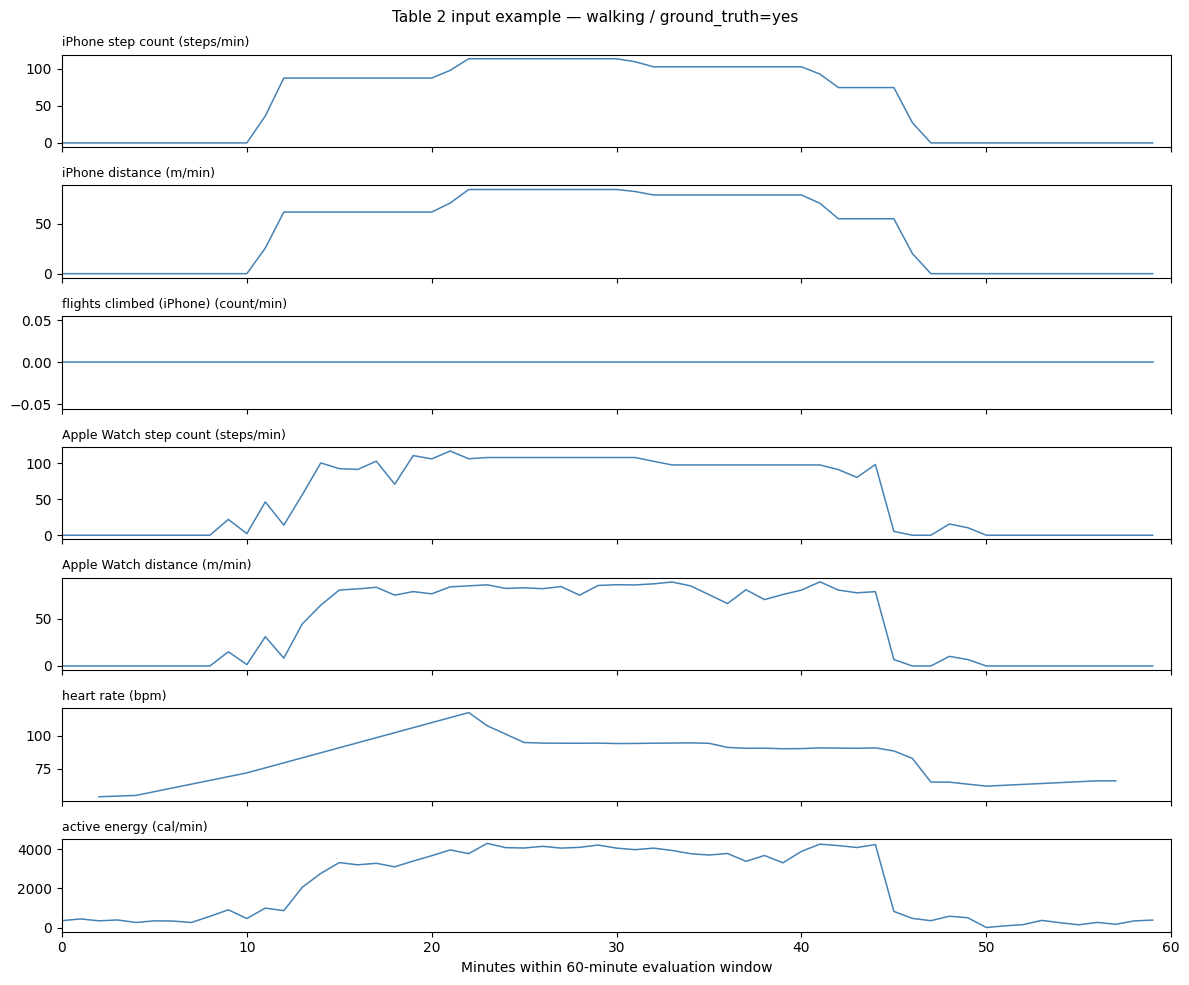

Saved: /Users/milanagurbanova/Coding_Projects/Stanford/SensorLM/notebooks/fig_activity_window_example.png


In [4]:
from evaluation.tasks.activity import ActivityTask
from time_series_datasets.mhc_activity_dataset import MHCActivityDataset, WORKOUT_LABELS

activity_ds = MHCActivityDataset(split='test', dataset_dir=str(DAILY_DIR), max_recordings=500)
activity_task = ActivityTask()

pos_by_type = Counter()
for s in activity_ds._samples:
    if s.ground_truth == 'yes':
        pos_by_type[WORKOUT_LABELS.get(s.workout_channel, s.workout_channel)] += 1

summary_rows = []
total_pos = sum(pos_by_type.values())
for label, count in sorted(pos_by_type.items(), key=lambda x: (-x[1], x[0])):
    summary_rows.append({'activity': label, 'positive_windows': count, 'pct_of_positive_windows': round(100 * count / total_pos, 2)})

display(pd.DataFrame(summary_rows))
print(f'Total activity samples in dataset object : {len(activity_ds)}')
print(f'Positive windows                         : {total_pos}')
print(f'Negative windows                         : {sum(1 for s in activity_ds._samples if s.ground_truth == "no")}')

fig, ax = plt.subplots(figsize=(10, 4))
activities = [row['activity'] for row in summary_rows]
counts = [row['positive_windows'] for row in summary_rows]
ax.barh(activities, counts, color='steelblue')
ax.set_xlabel('Positive windows (test split; first 500 recordings scanned)')
ax.set_title('Table 2 support plot — activity distribution in the current eval subset')
plt.tight_layout()
fig_path = FIG_DIR / 'fig_activity_distribution.png'
fig.savefig(fig_path, dpi=140, bbox_inches='tight')
plt.show()
print(f'Saved: {fig_path}')

sample_idx = next(i for i, s in enumerate(activity_ds._samples) if s.ground_truth == 'yes')
activity_sample = activity_ds[sample_idx]
print()
print('Example prompt for one positive activity window:')
print(activity_task.build_prompt(activity_sample))

fig, axes = plt.subplots(activity_sample.recording.values.shape[0], 1, figsize=(12, 10), sharex=True)
minutes = np.arange(activity_sample.recording.values.shape[1])
for ax, signal in zip(axes, activity_sample.recording.iter_channels()):
    valid = np.isfinite(signal.data)
    ax.plot(minutes[valid], signal.data[valid], color='steelblue', linewidth=1.1)
    title = signal.display_name if not signal.unit else f'{signal.display_name} ({signal.unit})'
    ax.set_title(title, fontsize=9, loc='left')
    ax.set_xlim(0, activity_sample.recording.values.shape[1])
axes[-1].set_xlabel('Minutes within 60-minute evaluation window')
fig.suptitle(
    f'Table 2 input example — {activity_sample.metadata["workout_label"]} / ground_truth={activity_sample.ground_truth}',
    fontsize=11,
)
plt.tight_layout()
fig_path = FIG_DIR / 'fig_activity_window_example.png'
fig.savefig(fig_path, dpi=140, bbox_inches='tight')
plt.show()
print(f'Saved: {fig_path}')


---
## Section 4 — Metabolic Evaluation Pipeline

**LaTeX references:** Table 3 and Table 6.

This section documents the weekly metabolic benchmark.

Important correction relative to some earlier notes: the current weekly eval path does **not** pass only 7 continuous channels. `WeeklyMHCTransformer` returns **all 19 hourly channels**:

- 7 continuous channels
- 2 sleep binary channels
- 10 workout binary channels

So the plotted-model baseline currently sees the full weekly sensor package, not just the continuous subset.

,label_column,task_type,n_non_null_users,positive_or_reference_class,class_distribution
0,BiologicalSex,binary,323,Male,"{'Male': 246, 'Female': 77}"
1,Diabetes,binary,122,True,"{'False': 113, 'True': 9}"
2,Hypertension,binary,122,True,"{'False': 90, 'True': 32}"
3,cardiovascular_disease,binary,233,True,"{False: 204, True: 29}"
4,BMI_categories,ordinal,299,Overweight,"{'Overweight': 113, 'Normal weight': 89, 'Obes..."
5,happiness_categories,ordinal,91,High,"{'High': 46, 'Very High': 22, 'Medium': 18, 'L..."
6,blood_pressure_categories,ordinal,121,Hypertension_Stage_1,"{'Hypertension_Stage_1': 44, 'Normal': 42, 'El..."
7,sleep_time_categories,ordinal,290,Short,"{'Normal': 182, 'Short': 66, 'Insufficient': 3..."
8,Atrial fibrillation (Afib),binary,233,True,"{False: 231, True: 2}"


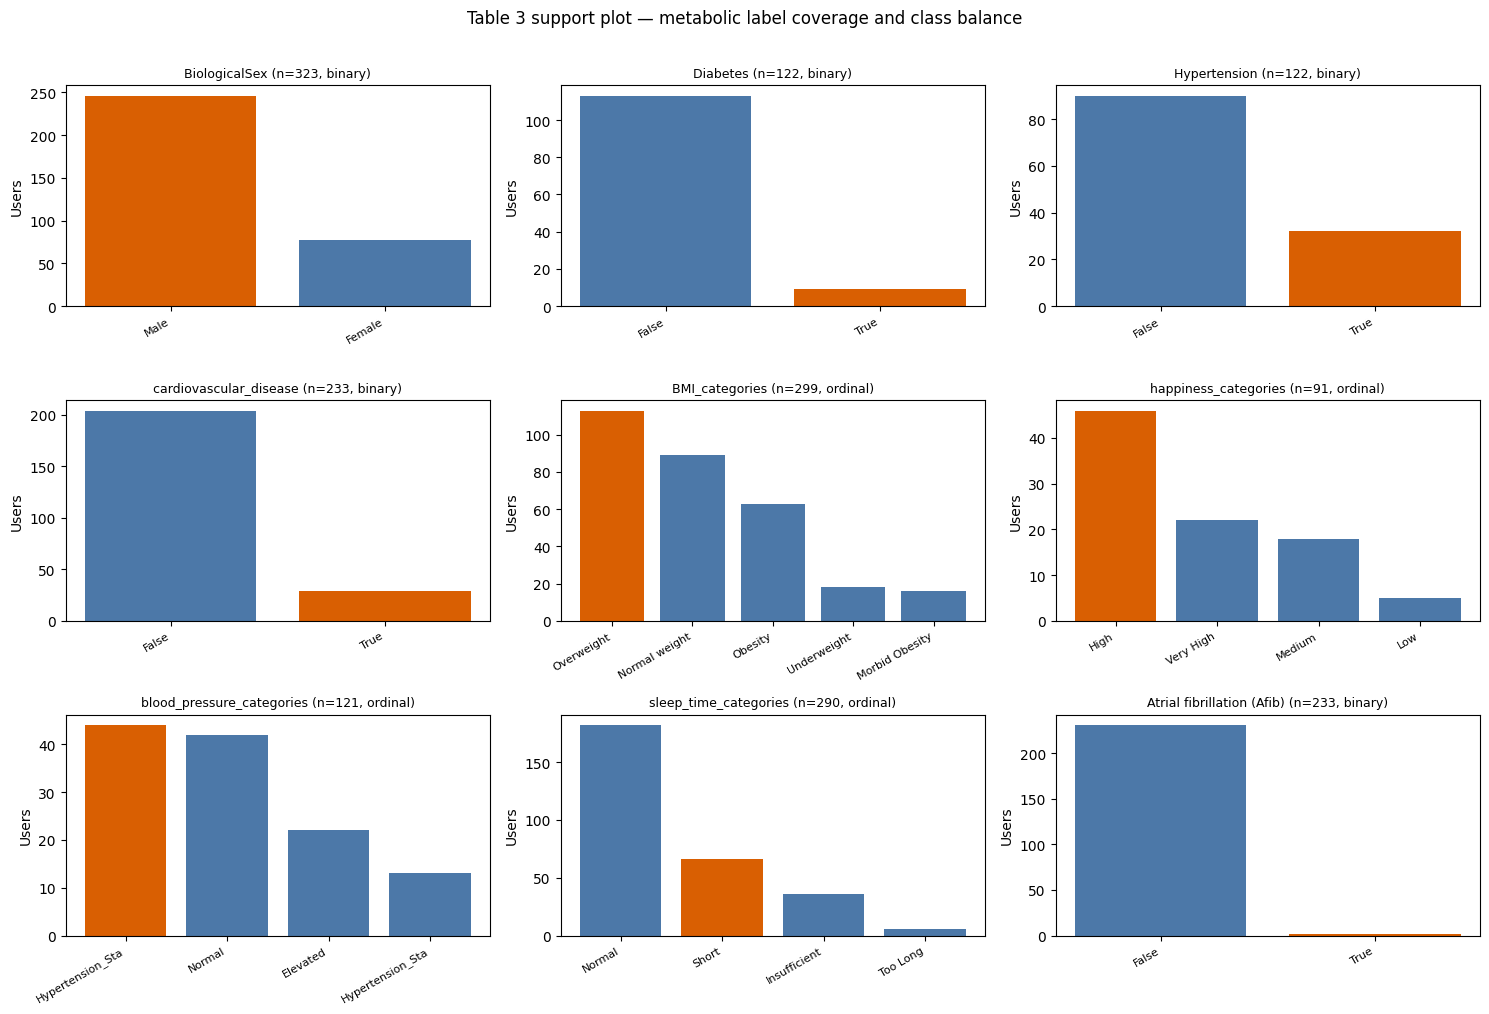

Saved: /Users/milanagurbanova/Coding_Projects/Stanford/SensorLM/notebooks/fig_metabolic_label_distributions.png


In [5]:
METABOLIC_COLS = {
    'BiologicalSex': ('binary', 'Male'),
    'Diabetes': ('binary', 'True'),
    'Hypertension': ('binary', 'True'),
    'cardiovascular_disease': ('binary', 'True'),
    'BMI_categories': ('ordinal', 'Overweight'),
    'happiness_categories': ('ordinal', 'High'),
    'blood_pressure_categories': ('ordinal', 'Hypertension_Stage_1'),
    'sleep_time_categories': ('ordinal', 'Short'),
    'Atrial fibrillation (Afib)': ('binary', 'True'),
}

coverage_rows = []
for col, (kind, positive) in METABOLIC_COLS.items():
    vc = labels_df[col].value_counts(dropna=True)
    coverage_rows.append({
        'label_column': col,
        'task_type': kind,
        'n_non_null_users': int(vc.sum()),
        'positive_or_reference_class': positive,
        'class_distribution': dict(vc),
    })

display(pd.DataFrame(coverage_rows))

fig, axes = plt.subplots(3, 3, figsize=(15, 10))
axes = axes.flatten()
for ax, (col, (kind, positive)) in zip(axes, METABOLIC_COLS.items()):
    vc = labels_df[col].value_counts(dropna=True)
    colors = ['#d95f02' if str(v) == str(positive) else '#4c78a8' for v in vc.index]
    ax.bar(range(len(vc)), vc.values, color=colors)
    ax.set_xticks(range(len(vc)))
    ax.set_xticklabels([str(v)[:16] for v in vc.index], rotation=30, ha='right', fontsize=8)
    ax.set_title(f'{col} (n={int(vc.sum())}, {kind})', fontsize=9)
    ax.set_ylabel('Users')
for ax in axes[len(METABOLIC_COLS):]:
    ax.set_visible(False)
fig.suptitle('Table 3 support plot — metabolic label coverage and class balance', fontsize=12, y=1.01)
plt.tight_layout()
fig_path = FIG_DIR / 'fig_metabolic_label_distributions.png'
fig.savefig(fig_path, dpi=140, bbox_inches='tight')
plt.show()
print(f'Saved: {fig_path}')


MHCMetabolicDataset (test, BiologicalSex): 8 samples
Dataset size (test split)         : 8
Example sample_id                 : 3175f32f-dfa2-4beb-9417-9af9cb8016c0:week:2018-02-21:BiologicalSex
Ground truth                      : Male
Recording shape (channels, hours) : (19, 168)
Continuous channels               : ('iPhone step count', 'iPhone distance', 'flights climbed (iPhone)', 'Apple Watch step count', 'Apple Watch distance', 'heart rate', 'active energy')
Binary channels                   : ('asleep', 'inbed', 'walking', 'cycling', 'running', 'other', 'mixed metabolic cardio training', 'traditional strength training', 'elliptical', 'high intensity interval training', 'functional strength training', 'yoga')

Prompt sent to the model:
You are a health informatics researcher analyzing anonymized Apple Watch sensor data.
This is a scientific evaluation benchmark — no real identities are involved.

The plots show one week (168 hours) of wearable sensor recordings from one anonymized 

/var/folders/bk/gkltkpvd01lgcjppsw_z_jh80000gn/T/ipykernel_83278/760817365.py:68: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


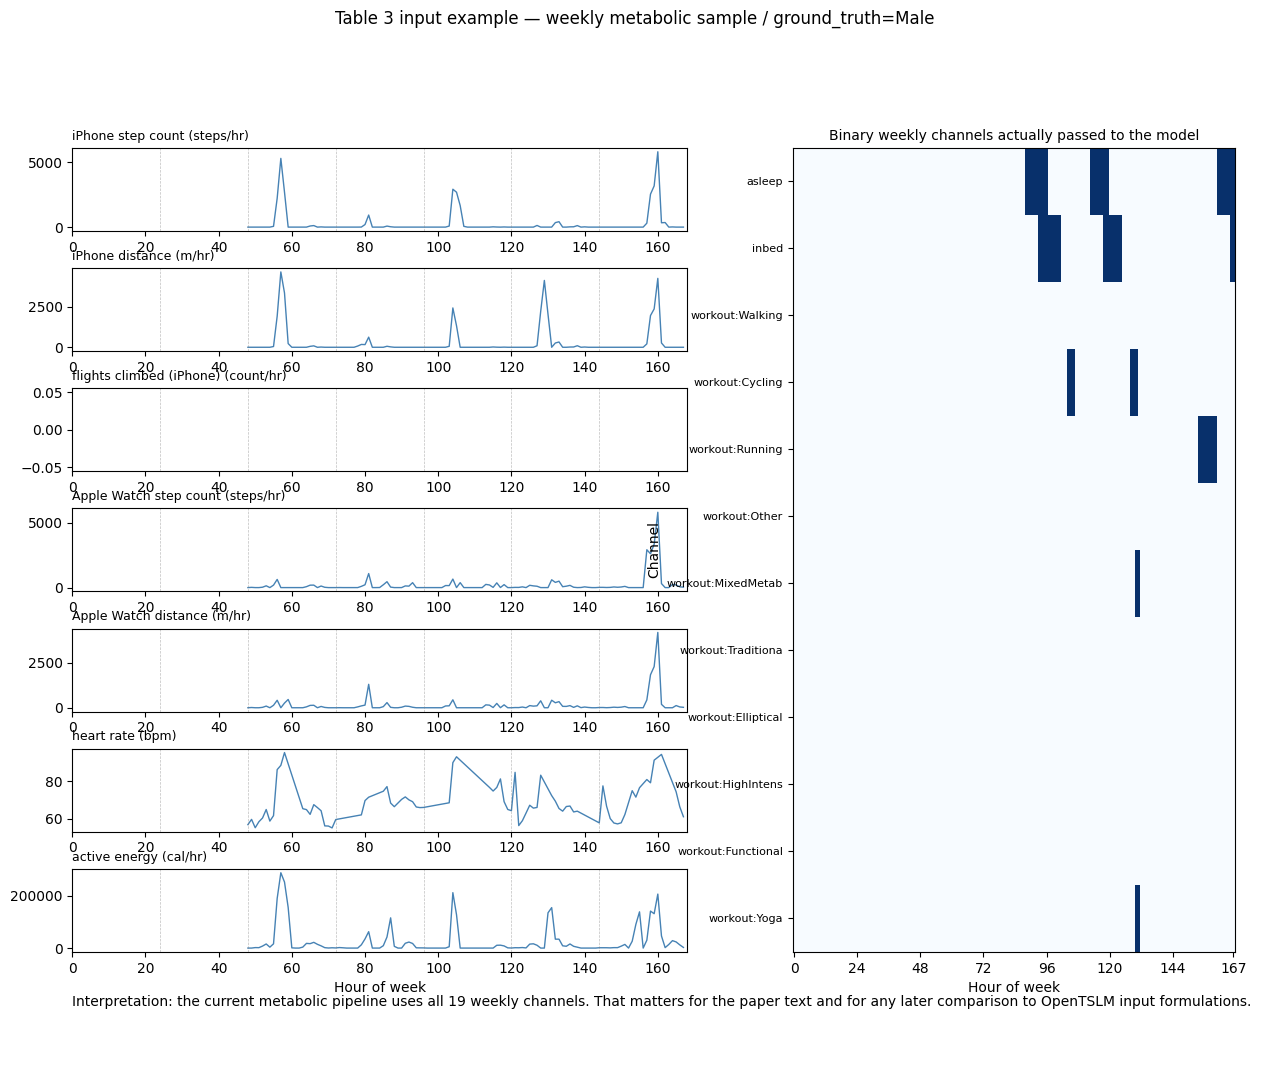

Saved: /Users/milanagurbanova/Coding_Projects/Stanford/SensorLM/notebooks/fig_weekly_metabolic_input_example.png


In [6]:
from evaluation.tasks.metabolic import MetabolicTask
from time_series_datasets.mhc_metabolic_dataset import MHCMetabolicDataset

metabolic_ds = MHCMetabolicDataset(
    label_column='BiologicalSex',
    label_values=['Male', 'Female'],
    split='test',
    dataset_dir=str(WEEKLY_DIR),
    labels_path=str(LABELS_PATH),
)
metabolic_task = MetabolicTask('BiologicalSex', 'metabolic_biological_sex')
metabolic_sample = metabolic_ds[0]

print(f'Dataset size (test split)         : {len(metabolic_ds)}')
print(f'Example sample_id                 : {metabolic_sample.sample_id}')
print(f'Ground truth                      : {metabolic_sample.ground_truth}')
print(f'Recording shape (channels, hours) : {metabolic_sample.recording.values.shape}')
print(f'Continuous channels               : {metabolic_sample.recording.display_names[:7]}')
print(f'Binary channels                   : {metabolic_sample.recording.display_names[7:]}')
print()
print('Prompt sent to the model:')
print(metabolic_task.build_prompt(metabolic_sample))

hours = np.arange(metabolic_sample.recording.values.shape[1])
fig = plt.figure(figsize=(15, 12))
gs = fig.add_gridspec(8, 2, width_ratios=[3.2, 2.3], hspace=0.45)

for i in range(7):
    ax = fig.add_subplot(gs[i, 0])
    data = metabolic_sample.recording.values[i]
    valid = np.isfinite(data)
    ax.plot(hours[valid], data[valid], color='steelblue', linewidth=1.0)
    ax.set_xlim(0, 168)
    ax.set_title(
        f'{metabolic_sample.recording.display_names[i]} ({metabolic_sample.recording.units[i]})',
        fontsize=9,
        loc='left',
    )
    for d in range(1, 7):
        ax.axvline(d * 24, color='gray', linewidth=0.5, linestyle='--', alpha=0.5)
    if i == 6:
        ax.set_xlabel('Hour of week')

ax_heat = fig.add_subplot(gs[:7, 1])
heat = np.nan_to_num(metabolic_sample.recording.values[7:], nan=0.0)
ax_heat.imshow(heat, aspect='auto', interpolation='nearest', cmap='Blues', vmin=0, vmax=1)
ax_heat.set_title('Binary weekly channels actually passed to the model', fontsize=10)
ax_heat.set_xlabel('Hour of week')
ax_heat.set_ylabel('Channel')
ax_heat.set_yticks(range(12))
ax_heat.set_yticklabels([name.replace('HKWorkoutActivityType', '').replace('sleep:', '')[:18] for name in metabolic_sample.recording.channel_names[7:]], fontsize=8)
ax_heat.set_xticks([0, 24, 48, 72, 96, 120, 144, 167])

ax_note = fig.add_subplot(gs[7, :])
ax_note.axis('off')
ax_note.text(
    0.0,
    0.8,
    'Interpretation: the current metabolic pipeline uses all 19 weekly channels. That matters for the paper text and for any later comparison to OpenTSLM input formulations.',
    fontsize=10,
)

fig.suptitle(
    f'Table 3 input example — weekly metabolic sample / ground_truth={metabolic_sample.ground_truth}',
    fontsize=12,
    y=0.995,
)
plt.tight_layout()
fig_path = FIG_DIR / 'fig_weekly_metabolic_input_example.png'
fig.savefig(fig_path, dpi=140, bbox_inches='tight')
plt.show()
print(f'Saved: {fig_path}')


---
## Section 5 — Concrete Missing Pieces

**LaTeX references:** Table 1 through Table 5.

### A. Missing at the project level

These are not just "evaluation pipeline" gaps. They are broader project gaps.

| Area | Why it matters | Current state |
|---|---|---|
| Export caption shards | Needed so `MHCCaptionQADataset` can actually train on generated captions | Code exists, exported shard directory is not present in repo |
| OpenTSLM Stage 1 training | Needed for the paper's official caption-trained / "zero-shot" rows | Not implemented in this repo |
| Stage 2 task fine-tuning | Needed for official fine-tuned rows | Not implemented in this repo |
| Retrieval scoring API | Needed for Table 5 | Not implemented in model interface |

### B. Missing specifically in the evaluation benchmark

| Paper target | What is still missing in code |
|---|---|
| Table 2 exact per-activity table | aggregate metrics by activity label and emit per-column results |
| Table 2 pairwise variant | separate dataset/task protocol |
| Table 3 Happiness/BP/Sleep category rows | register more metabolic label columns/tasks |
| Table 4 sleep 2-class | new dataset + task |
| Table 4 activity 8-class | new dataset + task |
| Table 5 retrieval | caption candidate pool + scoring backend + metrics |

### C. What the "training arm" means here

When earlier notes said **"training step missing"**, that means this repo currently has the data plumbing and prompt-based evaluation, but not the learned model path that would produce the paper's official trained rows:

- **Stage 1**: train on sensor-caption pairs
- **Stage 2**: fine-tune on downstream labels

So yes: that is conceptually part of the overall paper evaluation story, but it is **not** the same thing as the current `evaluation/run_eval.py` benchmark runner.

### D. Why `run_eval.py` does not pass `annotations`

Right now `run_eval.py` evaluates models from **raw plotted sensor channels only**. That is why `Evaluator.run()` calls:

```python
response = model.process(prompt=prompt, signals=signals)
```

and does **not** pass `annotations`.

That is correct for the current benchmark baseline.

Annotations would become relevant only if you want one of these extensions:

1. **caption-assisted evaluation**: feed generated captions/rationales together with the plots
2. **retrieval evaluation**: compare sensor input against candidate captions
3. **OpenTSLM-style learned caption pipeline**: generate training data and then evaluate the trained model

So: `annotations` are **not required** for the current Table 2 / Table 3 prompt-only runner. They become relevant once the benchmark should consume generated caption context rather than only raw sensor plots.

---
## Section 6 — Useful Commands

### Implemented benchmark runs

```bash
python evaluation/run_eval.py --dataset mhc_activity     --task activity     --model gpt-4o     --split test

python evaluation/run_eval.py --dataset mhc_metabolic_biological_sex     --task metabolic_biological_sex     --model gpt-4o     --split test

python evaluation/run_eval.py --dataset mhc_metabolic_diabetes     --task metabolic_diabetes     --model gpt-4o     --split test

python evaluation/run_eval.py --dataset mhc_metabolic_hypertension     --task metabolic_hypertension     --model gpt-4o     --split test

python evaluation/run_eval.py --dataset mhc_metabolic_cardiovascular     --task metabolic_cardiovascular     --model gpt-4o     --split test
```

### What `mhc_metabolic_dataset.py` is used for

It is the weekly dataset adapter behind the metabolic runs above. If Table 3 remains in scope, this file is needed. If the project dropped weekly metabolic prediction completely, this file would no longer be necessary.